In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from torch.utils.data import TensorDataset, DataLoader, random_split
import os
if os.environ.get("BACKGROUND"):
    from tqdm import tqdm as _tqdm
    LOG = open("progress.log", "a", buffering=1)

    class tqdm(_tqdm):
        def __init__(self, *args, **kwargs):
            kwargs.setdefault("file", LOG)
            kwargs.setdefault("mininterval", 10)   # update the file every 10 s
            super().__init__(*args, **kwargs)

        @classmethod
        def write(cls, s, file=None, **kwargs):
            super().write(s, file=file or LOG, **kwargs)
else:
    from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Using device: cuda
NVIDIA RTX A6000


In [2]:
#GLOBAL

NUM_SAMPLES = 25000
NUM_TIME_STEPS = 1000
T_MAX = 30.0
t_eval = np.linspace(0, T_MAX, NUM_TIME_STEPS)

# parameter ranges, column order: [alpha, beta, delta, gamma, omega, x0, v0]
PARAM_LOW  = np.array([-1.0, 0.1, 0.0, 0.0, 0.5, -2.0, -2.0])
PARAM_HIGH = np.array([ 1.0, 1.0, 0.5, 1.0, 1.5,  2.0,  2.0])

DATA_SEED  = 0
TRAIN_SEED = 0

In [3]:
#DUFFING DERIVATIVE

def duffing_deriv(t, state, alpha, beta, delta, gamma, omega):
    x, v = state
    dxdt = v
    dvdt = gamma * np.cos(omega * t) - delta * v - alpha * x - beta * (x**3)
    return [dxdt, dvdt]

In [4]:
#DATASET GENERATION

# increasing the share of chaotic trajectiories
HARD_FRAC  = 0.0            # share of training trajectories drawn from the hard region (0 = uniform)
HARD_ALPHA = (-1.0, 0.0)    # alpha defined as hard
HARD_DELTA = (0.0, 0.18)    # delta defined as hard

def sample_params_np(n, hard_frac=0.0):
    P = np.random.uniform(PARAM_LOW, PARAM_HIGH, size=(n, 7))
    n_hard = int(round(n * hard_frac))
    P[:n_hard, 0] = np.random.uniform(*HARD_ALPHA, n_hard)
    P[:n_hard, 2] = np.random.uniform(*HARD_DELTA, n_hard)
    return P[np.random.permutation(n)]

def generate_data(num_samples, hard_frac=0.0):
    X_data = sample_params_np(num_samples, hard_frac)
    Y_data = np.zeros((num_samples, NUM_TIME_STEPS))

    for i in tqdm(range(num_samples), desc="Generating data", unit="traj"):
        alpha, beta, delta, gamma, omega, x0, v0 = X_data[i]
        params = (alpha, beta, delta, gamma, omega)
        sol = solve_ivp(duffing_deriv, [0, T_MAX], [x0, v0], args=params, t_eval=t_eval,
                        method="DOP853", rtol=1e-8, atol=1e-10)
        Y_data[i] = sol.y[0]

    return torch.tensor(X_data, dtype=torch.float32), torch.tensor(Y_data, dtype=torch.float32)

In [5]:
#NEURAL NETWORK

NORMALIZE_INPUTS = False   # scale every input to [-1, 1] before the first layer
HARD_IC          = True    # build x(0) = x0 and dx/dt(0) = v0 into the output
TAU_C            = 1.0     # seconds; how quickly the network's own term switches on after t = 0

class DuffingNet(nn.Module):
    def __init__(self, input_dim=8, output_dim=1, normalize=NORMALIZE_INPUTS, hard_ic=HARD_IC):
        super(DuffingNet, self).__init__()
        self.normalize = normalize
        self.hard_ic = hard_ic

        # input ranges: the 7 parameters from GLOBAL, plus t / T_MAX in [0, 1]
        lo = torch.tensor(list(PARAM_LOW)  + [0.0], dtype=torch.float32)
        hi = torch.tensor(list(PARAM_HIGH) + [1.0], dtype=torch.float32)
        # not saved in checkpoints, so older models still load
        self.register_buffer("in_mid",  (hi + lo) / 2, persistent=False)
        self.register_buffer("in_half", (hi - lo) / 2, persistent=False)

        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.SiLU(),
            nn.Linear(64, 128),
            nn.SiLU(),
            nn.Linear(128, 256),
            nn.SiLU(),
            nn.Linear(256, 512),
            nn.SiLU(),
            nn.Linear(512, 512),
            nn.SiLU(),
            nn.Linear(512, 256),
            nn.SiLU(),
            nn.Linear(256, output_dim)
        )

    def forward(self, x):
        # x: (N, 8) = [alpha, beta, delta, gamma, omega, x0, v0, t / T_MAX]
        raw = x
        if self.normalize:
            x = (x - self.in_mid) / self.in_half   # every column now spans [-1, 1]
        out = self.net(x)
        if not self.hard_ic:
            return out

        # hard initial condition: exact x(0) = x0 and dx/dt(0) = v0, for any network output
        x0, v0 = raw[:, 5:6], raw[:, 6:7]
        t = raw[:, 7:8] * T_MAX                    # back to seconds
        s = 1 - torch.exp(-t / TAU_C)              # 0 at t = 0, slope 1/TAU_C, levels off at 1
        return x0 + v0 * TAU_C * s + s**2 * out


# time grid fed to the network, normalized to [0, 1] so t has a similar scale to the other inputs
t_grid = torch.tensor(t_eval / T_MAX, dtype=torch.float32, device=device)

def predict_trajectory(model, params, t=t_grid): # reshapes from input for a singular point to an input for the trajectory
    B, T = params.shape[0], t.shape[0]
    p  = params.unsqueeze(1).expand(B, T, params.shape[1])   # (B, T, 7)
    tt = t.view(1, T, 1).expand(B, T, 1)                      # (B, T, 1)
    inp = torch.cat([p, tt], dim=-1).reshape(B * T, -1)       # (B*T, 8)
    return model(inp).view(B, T)

In [6]:
#HYBRID LOSS

XI = 200           # weight balancing: XI is for physics
OMICRON = 40       # weight balancing: OMICRON is for data
N_COL = 2048        # random (params, t) collocation points per step
W_IC = 0.0          # weight of the initial-condition term inside the physics loss
PHYS_SCALE = 1.0    # adjust if losses are orders of magnitude different
PHYS_HARD_FRAC = HARD_FRAC   # share of physics points drawn from the hard region (0 = uniform)

# causal weighting of the physics residual
CAUSAL     = True   # False = plain average over all times
N_BINS     = 32     # time bins over [0, T_MAX]; N_COL must be divisible by N_BINS
CAUSAL_EPS = 1.0    # strictness: larger = later bins wait longer for earlier ones

p_low  = torch.tensor(PARAM_LOW,  dtype=torch.float32, device=device)
p_high = torch.tensor(PARAM_HIGH, dtype=torch.float32, device=device)

def sample_params(n, hard_frac=0.0):
    P = p_low + (p_high - p_low) * torch.rand(n, 7, device=device)
    n_hard = int(round(n * hard_frac))
    if n_hard > 0:
        P[:n_hard, 0] = HARD_ALPHA[0] + (HARD_ALPHA[1] - HARD_ALPHA[0]) * torch.rand(n_hard, device=device)
        P[:n_hard, 2] = HARD_DELTA[0] + (HARD_DELTA[1] - HARD_DELTA[0]) * torch.rand(n_hard, device=device)
    return P

causal_log = []   # mean bin weight of each training step; TRAINING reads and clears it every epoch

def causal_residual_loss(res2):
    # res2: squared residuals, ordered bin by bin (n / N_BINS points per bin)
    L = res2.view(N_BINS, -1).mean(dim=1)          # error of each time bin
    before = torch.cumsum(L, dim=0) - L             # sum of the errors of all EARLIER bins
    w = torch.exp(-CAUSAL_EPS * before).detach()    # weights are constants: no gradient through them
    causal_log.append(w.mean().detach())
    return torch.mean(w * L)

def physics_loss_fn(model, n=N_COL, hard_frac=PHYS_HARD_FRAC, causal=CAUSAL):
    with torch.enable_grad():
        params = sample_params(n, hard_frac)
        alpha, beta, delta, gamma, omega, x0, v0 = params.split(1, dim=1)   # each (n, 1)

        # times in seconds (the network sees t / T_MAX)
        if causal:
            assert n % N_BINS == 0, "N_COL must be divisible by N_BINS"
            # stratified: the same number of random times in every bin, bins in order
            bins = torch.arange(N_BINS, device=device).repeat_interleave(n // N_BINS).unsqueeze(1).float()
            t = ((bins + torch.rand_like(bins)) * (T_MAX / N_BINS)).requires_grad_(True)
        else:
            t = (T_MAX * torch.rand(n, 1, device=device)).requires_grad_(True)

        x    = model(torch.cat([params, t / T_MAX], dim=1))
        x_t  = torch.autograd.grad(x,   t, torch.ones_like(x),   create_graph=True)[0]
        x_tt = torch.autograd.grad(x_t, t, torch.ones_like(x_t), create_graph=True)[0]

        residual = x_tt + delta * x_t + alpha * x + beta * x**3 \
                   - gamma * torch.cos(omega * t)
        res2 = residual.squeeze(1) ** 2
        res_loss = causal_residual_loss(res2) if causal else res2.mean()

        # initial conditions: x(0) = x0, dx/dt(0) = v0 (skipped when they're built into the network)
        ic_loss = torch.zeros((), device=device)
        if W_IC > 0:
            t0  = torch.zeros(n, 1, device=device, requires_grad=True)
            x_0 = model(torch.cat([params, t0 / T_MAX], dim=1))
            v_0 = torch.autograd.grad(x_0, t0, torch.ones_like(x_0), create_graph=True)[0]
            ic_loss = torch.mean((x_0 - x0)**2 + (v_0 - v0)**2)

    return (res_loss + W_IC * ic_loss) / PHYS_SCALE

def compute_loss(model, batch_x, batch_y, xi=XI, omicron = OMICRON):
    pred = predict_trajectory(model, batch_x)
    truth_loss   = criterion(pred, batch_y)
    physics_loss = physics_loss_fn(model)
    total_loss   = xi * physics_loss + omicron * truth_loss
    return total_loss, truth_loss, physics_loss

In [7]:
#METRICS

TOLERANCE = 0.05   # absolute position tolerance for "within tolerance" accuracy

def evaluate_metrics(model, loader, tol=TOLERANCE, eps=1e-8):
    model.eval()
    rel_l2_all = []
    sq_err = torch.zeros((), device=device)
    hits   = torch.zeros((), device=device)
    total  = 0
    with torch.no_grad():
        for batch_x, batch_y in loader:
            pred = predict_trajectory(model, batch_x)          
            err  = pred - batch_y

            rel_l2_all.append(torch.norm(err, dim=1) / (torch.norm(batch_y, dim=1) + eps))
            sq_err += (err ** 2).sum()
            hits   += (err.abs() < tol).sum()
            total  += batch_y.numel()

    rel_l2_all = torch.cat(rel_l2_all)
    return {
        "rel_l2_mean":   rel_l2_all.mean().item(),
        "rel_l2_median": rel_l2_all.median().item(),
        "tol_acc":       (hits / total).item(),
        "truth_loss":    (sq_err / total).item(),   # same quantity as the training truth loss (MSE)
    }

In [8]:
#PLOTTING

PINK          = "#FF6FAE"
PASTEL_BLUE   = "#8EC5FF"
PASTEL_YELLOW = "#F8DE7E"
PASTEL_GREEN  = "#77DD77"
YELLOW        = "#F2C200"

# darker shades, used for the validation / second curve
PINK_DARK   = "#D63A82"
BLUE_DARK   = "#3F8FE0"
YELLOW_DARK = "#D4A017"
GREEN_DARK  = "#3FA34D"

LINE_W = 0.75   # line thickness

def mark_best(ax, ep, values, color, mode="min", vline=True):
    # put a star on the best epoch of a curve; return (epoch, value)
    values = np.asarray(values)
    i = int(np.argmin(values) if mode == "min" else np.argmax(values))
    ax.scatter(ep[i], values[i], marker="*", s=140, color=color,
               edgecolor="black", linewidth=0.7, zorder=5)
    if vline:
        ax.axvline(ep[i], color=color, ls=":", lw=1.0)
    return ep[i], values[i]

def plot_history(history, save_path=None):
    # loss history
    if not history:
        print("No epochs recorded yet.")
        return

    ep = np.arange(1, len(history["train_total"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    ax = axes[0]
    for key, light, dark, label in [("total", PINK,          PINK_DARK,   "total"),
                                    ("phys",  PASTEL_BLUE,   BLUE_DARK,   "physics"),
                                    ("truth", PASTEL_YELLOW, YELLOW_DARK, "ground truth")]:
        for split, color in [("train", light), ("val", dark)]:
            vals = np.array(history[f"{split}_{key}"])
            be, bv = mark_best(ax, ep, vals, color, vline=False)
            ax.plot(ep, vals, color=color, lw=LINE_W,
                    label=f"{label} ({split}) · min ep {be}: {bv:.3g}")
    ax.set_yscale("log")
    ax.set_title("Loss history")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

    # relative L2 error
    ax = axes[1]
    for key, color, label in [("val_rel_l2_mean",   PASTEL_GREEN, "mean"),
                              ("val_rel_l2_median", GREEN_DARK,   "median")]:
        vals = 100 * np.array(history[key])
        be, bv = mark_best(ax, ep, vals, color)
        ax.plot(ep, vals, color=color, lw=LINE_W,
                label=f"{label} · min ep {be}: {bv:.2f}%")
    ax.set_yscale("log")
    ax.set_title("Relative L2 error (validation)")
    ax.set_xlabel("epoch")
    ax.set_ylabel("%")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    # 3) tolerance based accuracy
    ax = axes[2]
    vals = 100 * np.array(history["val_tol_acc"])
    be, bv = mark_best(ax, ep, vals, YELLOW, mode="max")
    ax.plot(ep, vals, color=YELLOW, lw=LINE_W, label=f"max ep {be}: {bv:.2f}%")
    ax.set_ylim(0, 100)
    ax.set_title(f"Within ±{TOLERANCE} accuracy (validation)")
    ax.set_xlabel("epoch")
    ax.set_ylabel("%")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

In [9]:
#RUN LOG

import json, time, copy
from datetime import datetime, timedelta
from pathlib import Path
import pandas as pd

#change this to include a custom note about the training run
RUN_NOTE = "" 
RECORD_PRINT_FROM = 0.9   # only print new-best messages after this fraction of training

#below is ai generated json mumbo jumbo nobody cares

RUNS_DIR = Path("runs")
CHECKPOINT_METRIC = "val_rel_l2_median"  
WATCH = ["val_total", "val_rel_l2_mean", "val_rel_l2_median", "val_tol_acc"] 
BEST_MODE = {"val_tol_acc": "max"}

def is_better(key, new, old):
    if old is None:
        return True
    return new > old if BEST_MODE.get(key) == "max" else new < old

def new_run():
    RUNS_DIR.mkdir(exist_ok=True)
    nums = [int(p.name[1:]) for p in RUNS_DIR.glob("v*") if p.is_dir() and p.name[1:].isdigit()]
    run_number = max(nums, default=0) + 1
    run_dir = RUNS_DIR / f"v{run_number}"
    run_dir.mkdir()
    return run_number, run_dir

def describe_model(model):
    linears = [m for m in model.modules() if isinstance(m, nn.Linear)]
    acts = {type(m).__name__ for m in model.modules()
            if isinstance(m, (nn.GELU, nn.ReLU, nn.Tanh, nn.SiLU, nn.Sigmoid, nn.Softplus, nn.Mish))}
    layers = [linears[0].in_features] + [l.out_features for l in linears]
    return {
        "architecture": "-".join(map(str, layers)),      # e.g. 8-64-128-128-1
        "activation":   ",".join(sorted(acts)),
        "n_params":     sum(p.numel() for p in model.parameters()),
    }

def get_config(model, optimizer, scheduler, grad_clip, train_loader, val_loader, test_loader, epochs):
    group = optimizer.param_groups[0]
    return {
        "note": RUN_NOTE,
        "started": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        # data
        "num_samples": NUM_SAMPLES, "num_time_steps": NUM_TIME_STEPS, "t_max": T_MAX,
        "train_size": len(train_loader.dataset), "val_size": len(val_loader.dataset),
        "test_size": len(test_loader.dataset),
        "param_low": PARAM_LOW.tolist(), "param_high": PARAM_HIGH.tolist(),
        # loss
        "xi": XI, "n_col": N_COL, "w_ic": W_IC, "phys_scale": PHYS_SCALE, "tolerance": TOLERANCE,
        # training
        "epochs_planned": epochs, "batch_size": train_loader.batch_size,
        "optimizer": type(optimizer).__name__,
        "lr": group.get("initial_lr", group["lr"]),
        "scheduler": type(scheduler).__name__ if scheduler is not None else "none",
        "lr_min": getattr(scheduler, "eta_min", None),
        "cosine_epochs": getattr(scheduler, "T_max", None),
        "grad_clip": grad_clip,
        "weight_decay": group.get("weight_decay", 0.0),
        "patience": PATIENCE,
        "checkpoint_metric": CHECKPOINT_METRIC,
        # model
        **describe_model(model),
        "device": str(device),
        "normalize_inputs": NORMALIZE_INPUTS,
        "hard_frac": HARD_FRAC, "phys_hard_frac": PHYS_HARD_FRAC,
        "hard_alpha": list(HARD_ALPHA), "hard_delta": list(HARD_DELTA),
        "causal": CAUSAL, "causal_bins": N_BINS, "causal_eps": CAUSAL_EPS,
        "data_seed": DATA_SEED, "train_seed": TRAIN_SEED,
        "hard_ic": HARD_IC, "tau_c": TAU_C,
        "omicron": globals().get("OMICRON"),   # None if OMICRON is not defined in this notebook
    }

def summarize(history):
    summary = {"epochs_done": len(history["train_total"])}
    for k, vals in history.items():
        vals = np.asarray(vals)
        i = int(np.argmax(vals) if BEST_MODE.get(k) == "max" else np.argmin(vals))
        summary[f"best_{k}"]       = float(vals[i])
        summary[f"best_{k}_epoch"] = i + 1
        summary[f"final_{k}"]      = float(vals[-1])
    return summary

def print_progress(epoch, epochs, s, new_records=(), lr=None):
    star = f"  ★ new best: {', '.join(new_records)}" if new_records else ""
    lr_txt = f"  (lr {lr:.1e})" if lr is not None else ""
    tqdm.write(f"Epoch {epoch}/{epochs}{lr_txt}{star}\n"
               f"    Train total: {s['train_total']:.4f} (truth {s['train_truth']:.4f}, phys {s['train_phys']:.4f}) | "
               f"Val total: {s['val_total']:.4f} (truth {s['val_truth']:.4f}, phys {s['val_phys']:.4f})\n"
               f"    val rel L2: mean {s['val_rel_l2_mean']:.2%}, median {s['val_rel_l2_median']:.2%} | "
               f"within {TOLERANCE}: {s['val_tol_acc']:.2%}")

def final_test(model, run_number, run_dir, test_loader, best_epoch, last_epoch):
    """Score the best and the last model on the held-out test set (used only here)."""
    best_model = copy.deepcopy(model)
    best_model.load_state_dict(torch.load(run_dir / f"duffing_net_best_v{run_number}.pt",
                                          map_location=device))
    results = {}
    print(f"\nTest set ({len(test_loader.dataset)} trajectories, unseen in training and model selection):")
    for name, mdl, ep in [("best", best_model, best_epoch), ("last", model, last_epoch)]:
        m = evaluate_metrics(mdl, test_loader)
        results.update({f"test_{name}_{k}": v for k, v in m.items()})
        print(f"    {name} model (epoch {ep}): rel L2 mean {m['rel_l2_mean']:.2%}, "
              f"median {m['rel_l2_median']:.2%} | within {TOLERANCE}: {m['tol_acc']:.2%}")
    return results

def log_run(run_number, run_dir, config, history, best_epoch, final_state, train_time, test_results):
    torch.save(final_state, run_dir / f"duffing_net_last_v{run_number}.pt")

    summary = {"run": run_number,
               "train_time_min": round(train_time / 60, 2),
               "checkpoint_epoch": best_epoch,
               **test_results,
               **summarize(history)}

    with open(run_dir / "config.json", "w") as f:
        json.dump(config, f, indent=2)
    with open(run_dir / "summary.json", "w") as f:
        json.dump(summary, f, indent=2)
    hist_df = pd.DataFrame(history)
    hist_df.index = np.arange(1, len(hist_df) + 1)
    hist_df.to_csv(run_dir / "history.csv", index_label="epoch")

    row = pd.DataFrame([{**summary, **config}])
    table = RUNS_DIR / "runs.csv"
    if table.exists():
        row = pd.concat([pd.read_csv(table), row], ignore_index=True)
    row.to_csv(table, index=False)

    print(f"Run v{run_number} logged to {run_dir}  (best model from epoch {best_epoch})")

In [10]:
#DATA PREPROCESSING

class GPULoader:
    def __init__(self, X, Y, batch_size=32, shuffle=False):
        self.X, self.Y = X.to(device), Y.to(device)
        self.dataset = self.X
        self.batch_size, self.shuffle = batch_size, shuffle

    def __len__(self):
        return (len(self.X) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        n = len(self.X)
        idx = torch.randperm(n, device=device) if self.shuffle else torch.arange(n, device=device)
        for i in range(0, n, self.batch_size):
            j = idx[i:i + self.batch_size]
            yield self.X[j], self.Y[j]

VAL_FRAC   = 0.15
TEST_FRAC  = 0.01
BATCH_SIZE = 64

val_size   = int(round(NUM_SAMPLES * VAL_FRAC))
test_size  = int(round(NUM_SAMPLES * TEST_FRAC))
train_size = NUM_SAMPLES - val_size - test_size
assert min(train_size, val_size, test_size) > 0, "NUM_SAMPLES too small for this split"

data_sig = (NUM_SAMPLES, NUM_TIME_STEPS, T_MAX, PARAM_LOW.tolist(), PARAM_HIGH.tolist(),
            HARD_FRAC, HARD_ALPHA, HARD_DELTA, VAL_FRAC, TEST_FRAC, DATA_SEED)
if globals().get("_data_sig") != data_sig:
    np.random.seed(DATA_SEED)
    X_tr, Y_tr = generate_data(train_size, hard_frac=HARD_FRAC)
    X_ev, Y_ev = generate_data(val_size + test_size, hard_frac=0.0)
    _data_sig = data_sig
else:
    print("Data settings unchanged, reusing existing dataset")

in_hard = (X_tr[:, 0] < HARD_ALPHA[1]) & (X_tr[:, 2] < HARD_DELTA[1])
print(f"Split: train {train_size} | val {val_size} | test {test_size} | "
      f"hard-region share in training: {in_hard.float().mean():.0%}")

train_loader = GPULoader(X_tr, Y_tr, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = GPULoader(X_ev[:val_size], Y_ev[:val_size], batch_size=256)
test_loader  = GPULoader(X_ev[val_size:], Y_ev[val_size:], batch_size=256)

Split: train 21000 | val 3750 | test 250 | hard-region share in training: 18%


Starting run v33



Test set (250 trajectories, unseen in training and model selection):
    best model (epoch 1841): rel L2 mean 26.12%, median 11.57% | within 0.05: 58.15%
    last model (epoch 1900): rel L2 mean 26.08%, median 11.05% | within 0.05: 57.88%
Run v33 logged to runs/v33  (best model from epoch 1841)


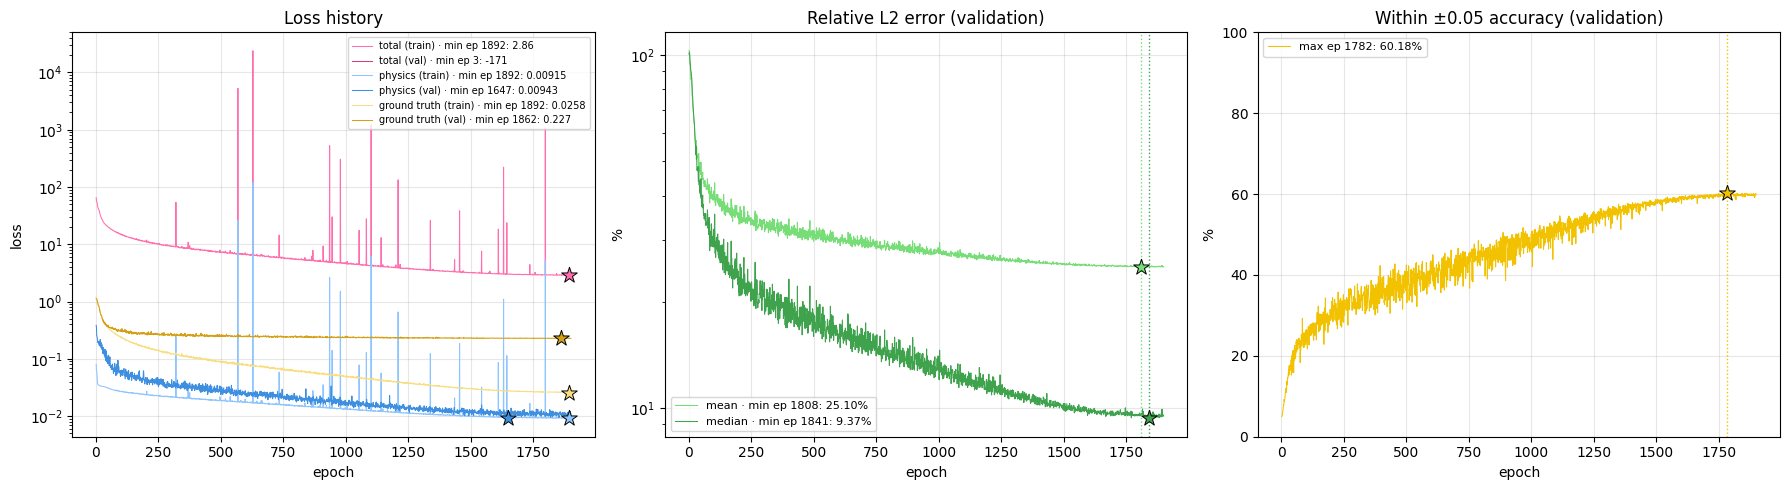

In [11]:
#TRAINING

LR              = 1e-3    # starting lr
LR_MIN          = 5e-5    # min lr
epochs          = 1900    # total epochs
COSINE_EPOCHS   = 1800    # epoch lr decline stops at (cosine annealing)
GRAD_CLIP       = 1.0     # max gradient norm per step (None = off)
WEIGHT_DECAY    = 1e-4    
PATIENCE        = None    # None turns early stopping off
VAL_PHYS_POINTS = 8192    # random points for the validation physics loss per epoch
PRINT_EVERY     = 500     # print results every this many epochs

torch.manual_seed(TRAIN_SEED)
np.random.seed(TRAIN_SEED)

model = DuffingNet().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=COSINE_EPOCHS, eta_min=LR_MIN)
history = {}

run_number, run_dir = new_run()
config = get_config(model, optimizer, scheduler, GRAD_CLIP, train_loader, val_loader, test_loader, epochs)
records = {k: None for k in WATCH}
best_score, best_epoch = None, None
causal_log.clear()   # start the run with an empty causal-weight log
print(f"Starting run v{run_number}")
start = time.time()

# one progress bar for the whole training, no per-epoch batch bar
epoch_bar = tqdm(range(epochs), desc=f"Run v{run_number}", unit="epoch")
try:
    for epoch in epoch_bar:
        lr_now = scheduler.get_last_lr()[0]  

        model.train()
        train_loss  = torch.zeros((), device=device)
        train_truth = torch.zeros((), device=device)
        train_phys  = torch.zeros((), device=device)
        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            loss, t_l, p_l = compute_loss(model, batch_x, batch_y)
            loss.backward()
            if GRAD_CLIP is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            train_loss  += loss.detach()
            train_truth += t_l.detach()
            train_phys  += p_l.detach()

        if scheduler.last_epoch < COSINE_EPOCHS:
            scheduler.step()

        m = evaluate_metrics(model, val_loader)
        val_truth = m.pop("truth_loss")
        # plain average over all times (no causal weights), so it stays comparable with older runs
        val_phys  = physics_loss_fn(model, n=VAL_PHYS_POINTS, hard_frac=0.0, causal=False).item()
        val_total = XI * val_phys + (1 - XI) * val_truth

        # average causal weight over this epoch's training steps (1.0 when causal weighting is off)
        causal_w = torch.stack(causal_log).mean().item() if causal_log else 1.0
        causal_log.clear()

        # record everything
        n_tr = len(train_loader)
        epoch_stats = {
            "train_total": train_loss.item() / n_tr,
            "train_truth": train_truth.item() / n_tr,
            "train_phys":  train_phys.item() / n_tr,
            "val_total":   val_total,
            "val_truth":   val_truth,
            "val_phys":    val_phys,
            **{f"val_{k}": v for k, v in m.items()},
            "causal_w_mean": causal_w,
        }
        for k, v in epoch_stats.items():
            history.setdefault(k, []).append(v)

        if is_better(CHECKPOINT_METRIC, epoch_stats[CHECKPOINT_METRIC], best_score):
            best_score = epoch_stats[CHECKPOINT_METRIC]
            best_epoch = epoch + 1
            torch.save(model.state_dict(), run_dir / f"duffing_net_best_v{run_number}.pt")

        per_epoch = (time.time() - start) / (epoch + 1)
        finish = datetime.now() + timedelta(seconds=per_epoch * (epochs - epoch - 1))

        epoch_bar.set_postfix(loss=f"{epoch_stats['train_total']:.4f}",
                              val_L2=f"{epoch_stats['val_rel_l2_median']:.2%}",
                              tol=f"{epoch_stats['val_tol_acc']:.1%}",
                              lr=f"{lr_now:.1e}",
                              w=f"{causal_w:.2f}",
                              done=finish.strftime("%a %H:%M"),
                              best_ep=best_epoch,)

        # new bests are tracked all the time, but only printed after RECORD_PRINT_FROM of training
        new_records = [k for k in WATCH if is_better(k, epoch_stats[k], records[k])]
        for k in new_records:
            records[k] = epoch_stats[k]

        late = (epoch + 1) > RECORD_PRINT_FROM * epochs
        shown_records = new_records if late else []

        if shown_records or (epoch + 1) % PRINT_EVERY == 0:
            print_progress(epoch + 1, epochs, epoch_stats, shown_records, lr=lr_now)

        # early stopping
        if PATIENCE is not None and (epoch + 1) - best_epoch >= PATIENCE:
            tqdm.write(f"\nEarly stop at epoch {epoch+1}: no improvement in "
                       f"{CHECKPOINT_METRIC} since epoch {best_epoch}")
            break

except KeyboardInterrupt:
    tqdm.write(f"\nStopped early after {len(history.get('train_total', []))} epochs")
finally:
    epoch_bar.close()

train_time = time.time() - start

if history:
    epochs_done = len(history["train_total"])
    test_results = final_test(model, run_number, run_dir, test_loader, best_epoch, epochs_done)
    log_run(run_number, run_dir, config, history, best_epoch, model.state_dict(), train_time, test_results)
    plot_history(history, save_path=run_dir / "plots.png")
else:
    run_dir.rmdir()
    print("No epochs completed, nothing logged.")

Run v33, 3750 trajectories
  rel L2: median 9.37%, mean 25.20%
  share of trajectories:  < 5%: 31.0% | < 10%: 51.4% | > 50%: 20.5%
  RMS error, first third of time: 0.1257 | last third: 0.6449  (ratio 5.1x)
  median rel L2, alpha < 0 (double well): 30.51% | alpha >= 0: 5.56%
  parameter means, worst 10% vs all:
    alpha: -0.58  vs  +0.00
     beta: +0.51  vs  +0.55
    delta: +0.19  vs  +0.25
    gamma: +0.53  vs  +0.49
    omega: +1.10  vs  +1.00
       x0: -0.12  vs  +0.00
       v0: -0.25  vs  -0.03
  causal weight w: start 0.05 | epoch 100 0.57 | end 0.89 (max 0.89)


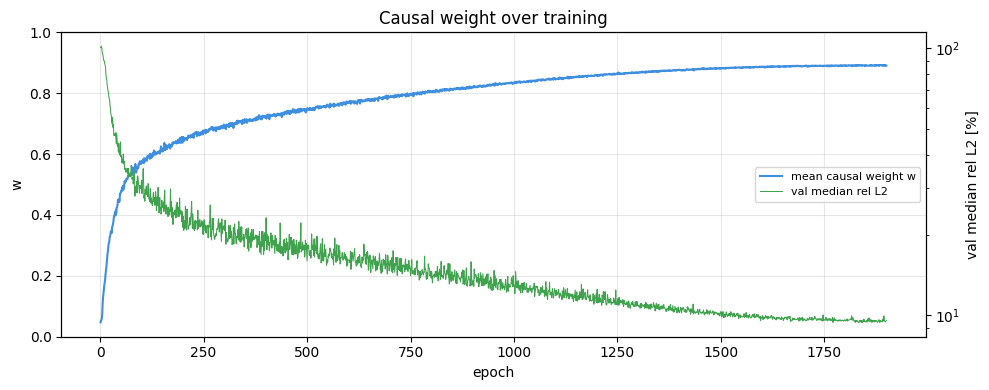

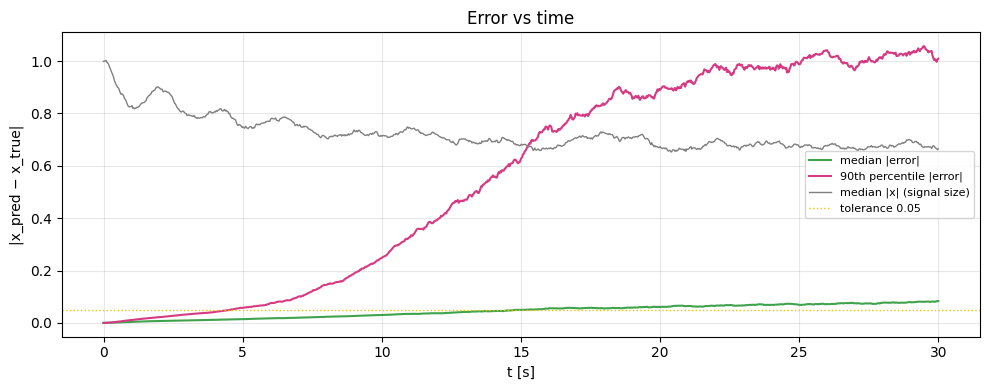

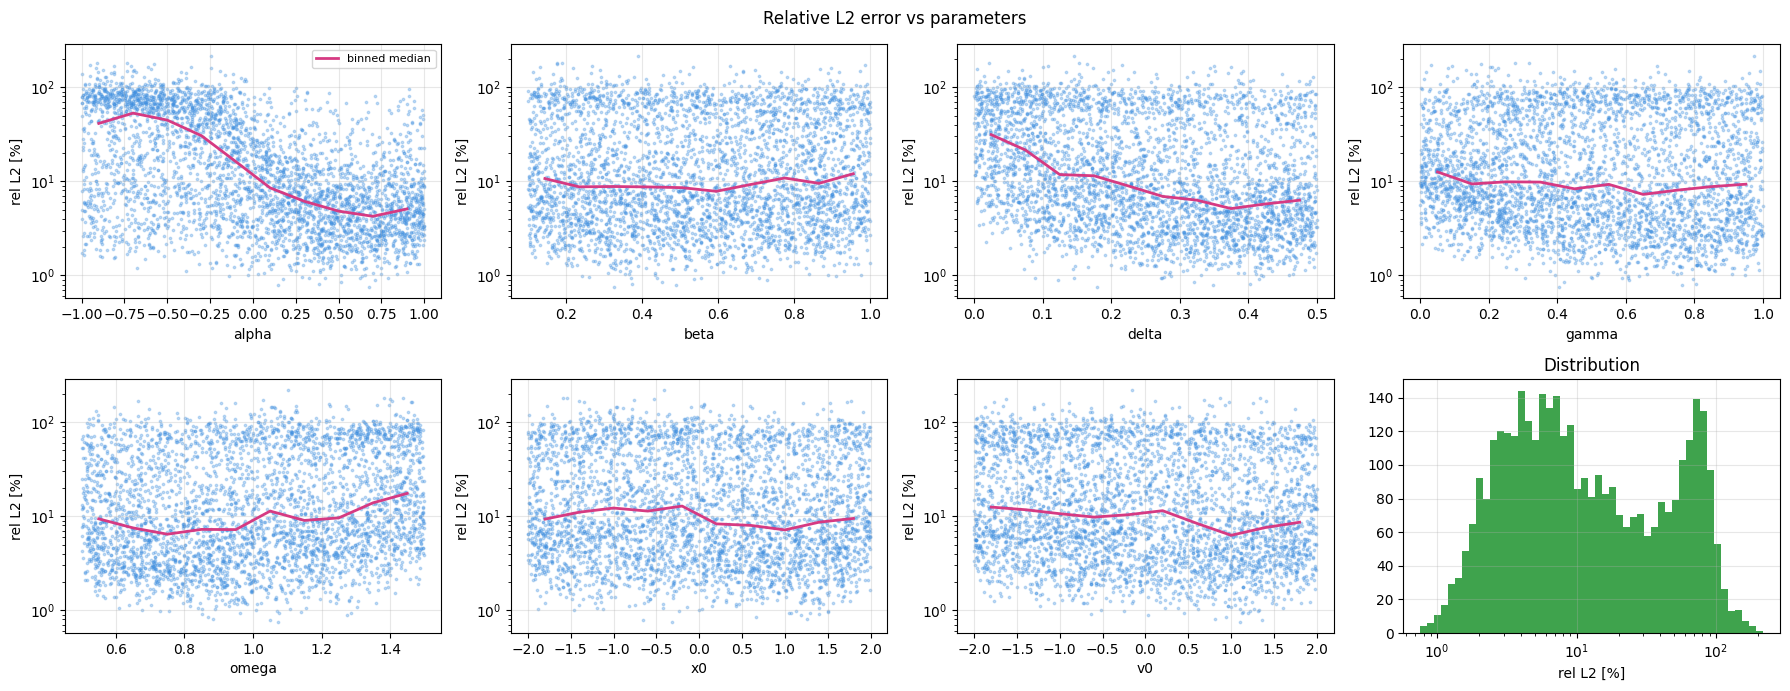

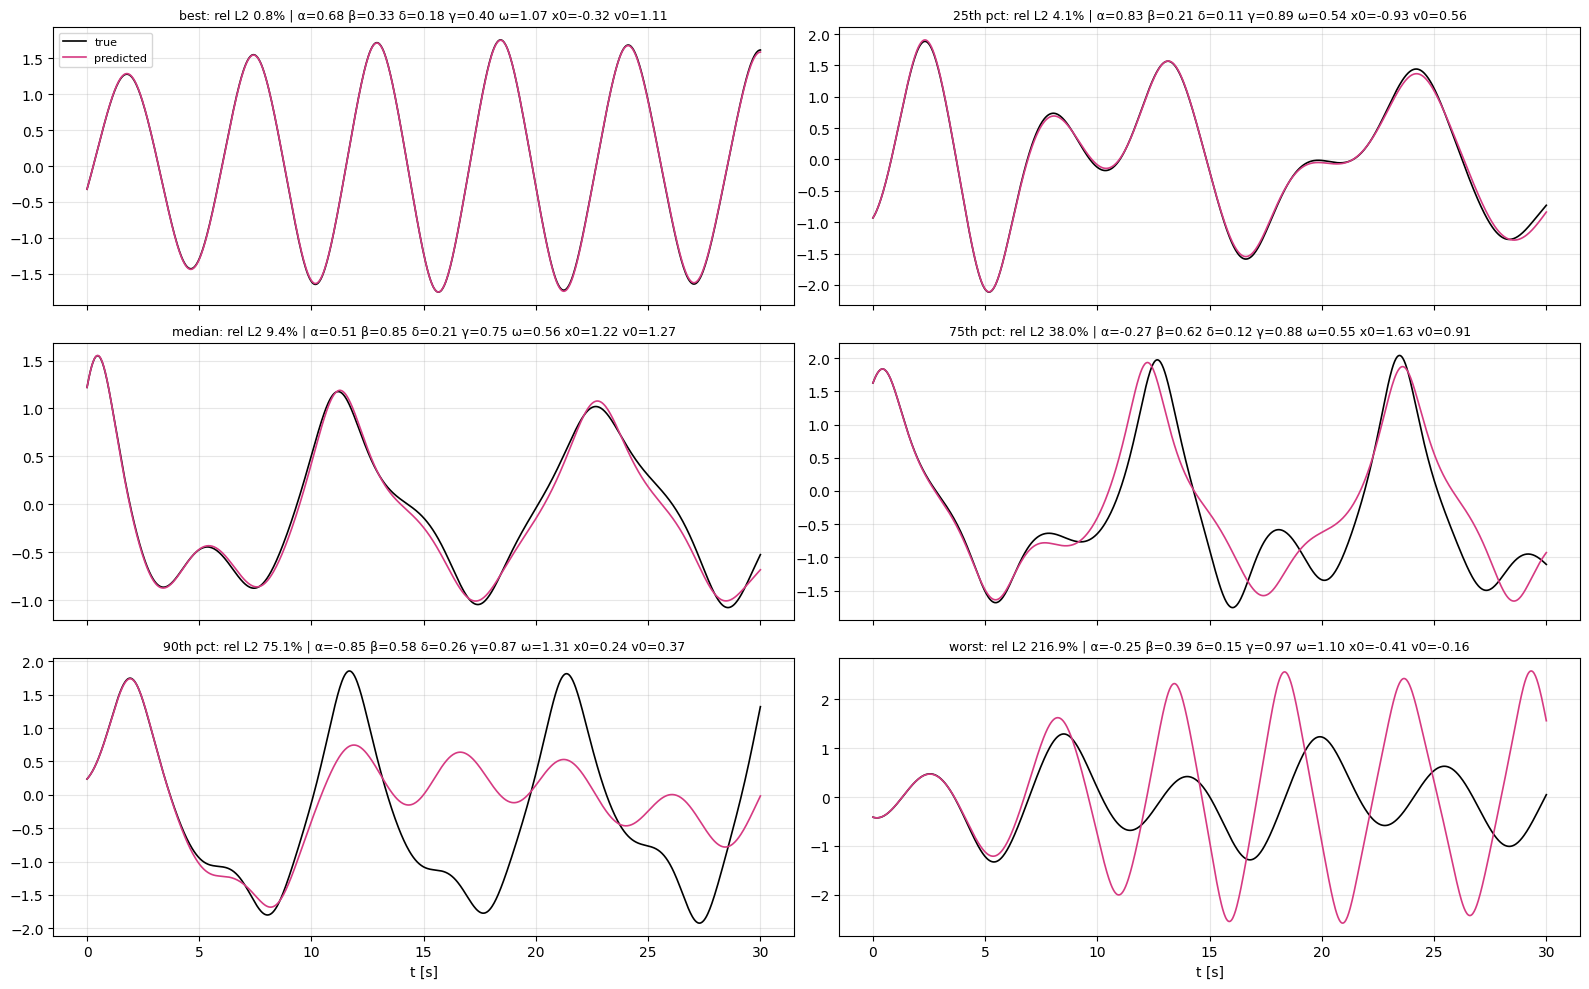

In [12]:
#DIAGNOSTICS

RUN_TO_ANALYZE = run_number     # change to run number if not run immediately after training, BEWARE THE CORRECT MODEL ARCHITECTURE
LOADER         = val_loader

diag_dir = RUNS_DIR / f"v{RUN_TO_ANALYZE}"
diag_model = DuffingNet().to(device)
diag_model.load_state_dict(torch.load(diag_dir / f"duffing_net_best_v{RUN_TO_ANALYZE}.pt", map_location=device))
diag_model.eval()

P, Yt, Yp = [], [], []
with torch.no_grad():
    for bx, by in LOADER:
        P.append(bx.cpu()); Yt.append(by.cpu()); Yp.append(predict_trajectory(diag_model, bx).cpu())
P, Yt, Yp = torch.cat(P).numpy(), torch.cat(Yt).numpy(), torch.cat(Yp).numpy()
err = Yp - Yt
rel = np.linalg.norm(err, axis=1) / (np.linalg.norm(Yt, axis=1) + 1e-8)
names = ["alpha", "beta", "delta", "gamma", "omega", "x0", "v0"]

third = NUM_TIME_STEPS // 3
early = np.sqrt(np.mean(err[:, :third] ** 2))
late  = np.sqrt(np.mean(err[:, -third:] ** 2))
neg   = P[:, 0] < 0
worst = rel > np.quantile(rel, 0.9)

print(f"Run v{RUN_TO_ANALYZE}, {len(rel)} trajectories")
print(f"  rel L2: median {np.median(rel):.2%}, mean {rel.mean():.2%}")
print(f"  share of trajectories:  < 5%: {np.mean(rel < 0.05):.1%} | < 10%: {np.mean(rel < 0.10):.1%} | > 50%: {np.mean(rel > 0.5):.1%}")
print(f"  RMS error, first third of time: {early:.4f} | last third: {late:.4f}  (ratio {late / early:.1f}x)")
print(f"  median rel L2, alpha < 0 (double well): {np.median(rel[neg]):.2%} | alpha >= 0: {np.median(rel[~neg]):.2%}")
print("  parameter means, worst 10% vs all:")
for i, n in enumerate(names):
    print(f"    {n:>5}: {P[worst, i].mean():+.2f}  vs  {P[:, i].mean():+.2f}")

# causal weight over training (only for runs trained with causal weighting)
hist_path = diag_dir / "history.csv"
h = pd.read_csv(hist_path) if hist_path.exists() else None
if h is not None and "causal_w_mean" in h.columns:
    w_hist = h["causal_w_mean"]
    print(f"  causal weight w: start {w_hist.iloc[0]:.2f} | epoch 100 {w_hist.iloc[min(99, len(w_hist) - 1)]:.2f} | "
          f"end {w_hist.iloc[-1]:.2f} (max {w_hist.max():.2f})")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(h["epoch"], w_hist, color=BLUE_DARK, lw=1.5, label="mean causal weight w")
    ax.set_ylim(0, 1)
    ax.set_xlabel("epoch")
    ax.set_ylabel("w")
    ax.grid(alpha=0.3)

    ax2 = ax.twinx()   # validation median on its own axis, to compare with how w unlocks
    ax2.plot(h["epoch"], 100 * h["val_rel_l2_median"], color=GREEN_DARK, lw=LINE_W, label="val median rel L2")
    ax2.set_yscale("log")
    ax2.set_ylabel("val median rel L2 [%]")

    lines = ax.get_lines() + ax2.get_lines()
    ax.legend(lines, [l.get_label() for l in lines], fontsize=8, loc="center right")
    ax.set_title("Causal weight over training")
    plt.tight_layout()
    fig.savefig(diag_dir / "diag_causal_w.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("  (no causal weight history for this run)")

#  error vs time (distance from t = 0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_eval, np.median(np.abs(err), axis=0),            color=GREEN_DARK, lw=1.5, label="median |error|")
ax.plot(t_eval, np.quantile(np.abs(err), 0.9, axis=0),     color=PINK_DARK,  lw=1.5, label="90th percentile |error|")
ax.plot(t_eval, np.median(np.abs(Yt), axis=0),             color="gray",     lw=1.0, label="median |x| (signal size)")
ax.axhline(TOLERANCE, color=YELLOW, lw=1.0, ls=":", label=f"tolerance {TOLERANCE}")
ax.set_title("Error vs time")
ax.set_xlabel("t [s]")
ax.set_ylabel("|x_pred − x_true|")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(diag_dir / "diag_error_vs_time.png", dpi=150, bbox_inches="tight")
plt.show()

# error vs each parameter
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, name in enumerate(names):
    ax = axes.flat[i]
    ax.scatter(P[:, i], 100 * rel, s=3, alpha=0.3, color=BLUE_DARK)
    bins = np.linspace(PARAM_LOW[i], PARAM_HIGH[i], 11)
    idx = np.clip(np.digitize(P[:, i], bins) - 1, 0, 9)
    centers = 0.5 * (bins[1:] + bins[:-1])
    med = [np.median(100 * rel[idx == b]) if np.any(idx == b) else np.nan for b in range(10)]
    ax.plot(centers, med, color=PINK_DARK, lw=2, label="binned median")
    ax.set_yscale("log")
    ax.set_xlabel(name)
    ax.set_ylabel("rel L2 [%]")
    ax.grid(alpha=0.3)
axes.flat[0].legend(fontsize=8)

ax = axes.flat[7]
lo = max(100 * rel.min(), 1e-2)
ax.hist(100 * rel, bins=np.logspace(np.log10(lo), np.log10(100 * rel.max()), 50), color=GREEN_DARK)
ax.set_xscale("log")
ax.set_xlabel("rel L2 [%]")
ax.set_title("Distribution")
ax.grid(alpha=0.3)
fig.suptitle("Relative L2 error vs parameters")
plt.tight_layout()
fig.savefig(diag_dir / "diag_error_vs_params.png", dpi=150, bbox_inches="tight")
plt.show()

# example trajectories
order = np.argsort(rel)
n = len(order)
picks = [("best", order[0]), ("25th pct", order[n // 4]), ("median", order[n // 2]),
         ("75th pct", order[3 * n // 4]), ("90th pct", order[int(0.9 * n)]), ("worst", order[-1])]

fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)
for ax, (label, i) in zip(axes.flat, picks):
    a, b, d, g, w, x0, v0 = P[i]
    ax.plot(t_eval, Yt[i], color="black",   lw=1.2, label="true")
    ax.plot(t_eval, Yp[i], color=PINK_DARK, lw=1.2, label="predicted")
    ax.set_title(f"{label}: rel L2 {rel[i]:.1%} | α={a:.2f} β={b:.2f} δ={d:.2f} γ={g:.2f} ω={w:.2f} "
                 f"x0={x0:.2f} v0={v0:.2f}", fontsize=9)
    ax.grid(alpha=0.3)
axes.flat[0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("t [s]")
plt.tight_layout()
fig.savefig(diag_dir / "diag_examples.png", dpi=150, bbox_inches="tight")
plt.show()